# Stock Performance and Risk Analysis

## Objective

This notebook compares the historical performance and risk of five major Indian equities: Reliance Industries, TCS, Infosys, HDFC Bank, and ICICI Bank.

We examine adjusted closing prices, normalized price series, daily returns, correlation, daily volatility, and cumulative price return.

**Sample period:** 2020-01-01 to 2025-12-31. The download's `end` date is exclusive.

**Interpretation note:** Historical performance metrics are descriptive, not forecasts. The average return and standard deviation below are daily statistics unless explicitly annualized.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

stocks = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS", "ICICIBANK.NS"]

data = yf.download(
    stocks,
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError("No data was downloaded. Check the tickers, date range, or internet connection.")

## Downloading the Data

`yfinance` returns a time-indexed dataset with price fields for each ticker. We use `auto_adjust=True`, so the `Close` series is adjusted for corporate actions and is more suitable for historical return calculations.

In [2]:
data.head()

Price            Close                                                    \
Ticker     HDFCBANK.NS ICICIBANK.NS     INFY.NS RELIANCE.NS       TCS.NS   
Date                                                                       
2020-01-01  595.677307   514.797852  619.740295  672.216125  1821.426880   
2020-01-02  599.474182   518.490417  617.931946  683.660278  1813.066040   
2020-01-03  590.925232   516.812073  627.436096  684.484070  1849.198975   
2020-01-06  578.136719   504.199890  621.422424  668.609314  1849.030518   
2020-01-07  587.291321   501.514343  612.212769  678.895569  1853.568359   

Price             High                                                    ...  \
Ticker     HDFCBANK.NS ICICIBANK.NS     INFY.NS RELIANCE.NS       TCS.NS  ...   
Date                                                                      ...   
2020-01-01  596.329554   520.312686  622.389677  680.008790  1835.123549  ...   
2020-01-02  600.056535   519.737297  623.062434  686.176208  1831.804697  ...   
2020-01-03  598.658868   518.682333  629.118230  686.487896  1867.979689  ...   
2020-01-06  587.850412   515.277506  633.996388  680.365044  1870.458080  ...   
2020-01-07  592.346133   513.694889  624.576414  683.303975  1860.962805  ...   

Price             Open                                                    \
Ticker     HDFCBANK.NS ICICIBANK.NS     INFY.NS RELIANCE.NS       TCS.NS   
Date                                                                       
2020-01-01  594.512601   517.819045  618.184342  675.956609  1821.762916   
2020-01-02  595.863594   514.078573  621.464438  673.284921  1831.804697   
2020-01-03  597.354375   515.996859  617.259204  682.636062  1818.402181   
2020-01-06  587.011801   515.277506  627.520161  676.847260  1852.853908   
2020-01-07  586.499343   509.570763  620.707526  676.401873  1849.072690   

Price           Volume                                             
Ticker     HDFCBANK.NS ICICIBANK.NS  INFY.NS RELIANCE.NS   TCS.NS  
Date                                                               
2020-01-01     3673698      7642793  2112415    14004468  1354908  
2020-01-02     6137166     10264223  5658200    17710316  2380752  
2020-01-03    10855550      9594690  7882938    20984698  4655761  
2020-01-06    10890186     12534334  6519403    24519177  3023209  
2020-01-07    14724494     16101835  7899363    16683622  2429317  

[5 rows x 25 columns]

In [3]:
data.columns

MultiIndex([( 'Close',  'HDFCBANK.NS'),
            ( 'Close', 'ICICIBANK.NS'),
            ( 'Close',      'INFY.NS'),
            ( 'Close',  'RELIANCE.NS'),
            ( 'Close',       'TCS.NS'),
            (  'High',  'HDFCBANK.NS'),
            (  'High', 'ICICIBANK.NS'),
            (  'High',      'INFY.NS'),
            (  'High',  'RELIANCE.NS'),
            (  'High',       'TCS.NS'),
            (   'Low',  'HDFCBANK.NS'),
            (   'Low', 'ICICIBANK.NS'),
            (   'Low',      'INFY.NS'),
            (   'Low',  'RELIANCE.NS'),
            (   'Low',       'TCS.NS'),
            (  'Open',  'HDFCBANK.NS'),
            (  'Open', 'ICICIBANK.NS'),
            (  'Open',      'INFY.NS'),
            (  'Open',  'RELIANCE.NS'),
            (  'Open',       'TCS.NS'),
            ('Volume',  'HDFCBANK.NS'),
            ('Volume', 'ICICIBANK.NS'),
            ('Volume',      'INFY.NS'),
            ('Volume',  'RELIANCE.NS'),
            ('Volume',       'TCS.NS')],

## Extracting the daily closing prices of the stocks :-

In [4]:
close_prices = data["Close"].reindex(columns=stocks)
close_prices = close_prices.dropna(how="all")
close_prices.head()

Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Date,,,,,
2020-01-01,672.216125,1821.426880,619.740295,595.677307,514.797852
2020-01-02,683.660278,1813.066040,617.931946,599.474182,518.490417
2020-01-03,684.484070,1849.198975,627.436096,590.925232,516.812073
2020-01-06,668.609314,1849.030518,621.422424,578.136719,504.199890
2020-01-07,678.895569,1853.568359,612.212769,587.291321,501.514343


The columns are explicitly reordered to match the `stocks` list. This matters later because portfolio weights must be applied to returns in exactly the same asset order.

## Plotting daily closing prices of all these stocks :-

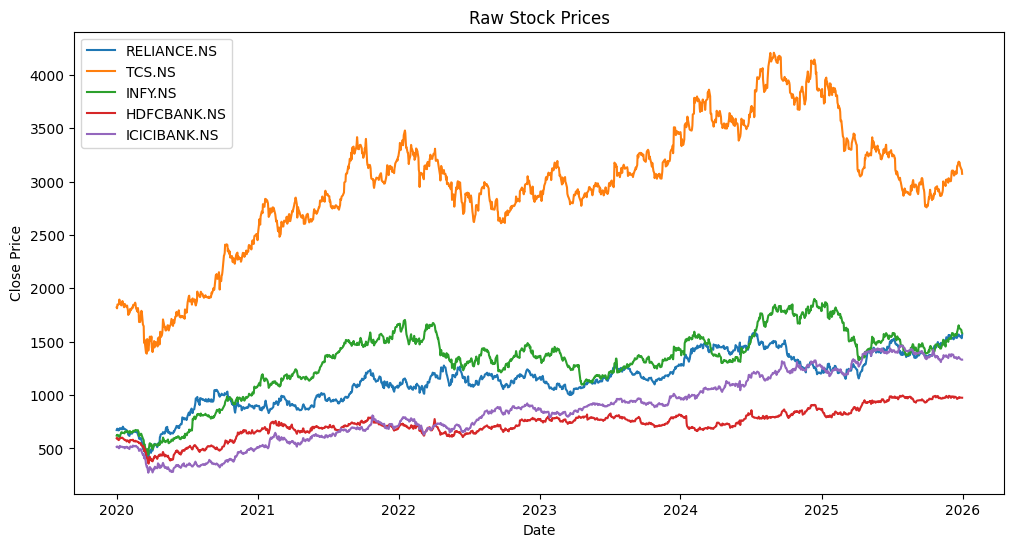

In [5]:
plt.figure(figsize=(12, 6))
for stock in close_prices.columns:
    plt.plot(close_prices.index, close_prices[stock], label=stock)
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.title('Raw Stock Prices')
plt.legend()
plt.show()

## OBSERVATION
Raw prices are difficult to compare because
each stock starts at a different price level.

## Price Normalization

Raw prices are difficult to compare because each stock starts at a different price level. A stock trading at ₹4,000 is not necessarily performing better than one trading at ₹500.

We normalize each price series by dividing every observation by its first available price:

$$
P^{(norm)}_{i,t} = \frac{P_{i,t}}{P_{i,0}}.
$$

Every normalized series starts at 1. A value of 1.25 means the price is 25% above its starting level; a value of 0.80 means it is 20% below its starting level.

This compares price performance from a common baseline. It does not compare company size, valuation, or absolute share price.

## Normalizing Prices

The first row is used as the baseline for each stock. Since the selected tickers generally have data over the same period, this provides a common starting point for visual comparison.

In [6]:
first_valid_prices = close_prices.apply(lambda column: column.dropna().iloc[0])
normalized_prices = close_prices.div(first_valid_prices, axis="columns")
normalized_prices.head()

Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Date,,,,,
2020-01-01,1.000000,1.000000,1.000000,1.000000,1.000000
2020-01-02,1.017025,0.995410,0.997082,1.006374,1.007173
2020-01-03,1.018250,1.015247,1.012418,0.992022,1.003913
2020-01-06,0.994634,1.015155,1.002714,0.970554,0.979413
2020-01-07,1.009936,1.017646,0.987854,0.985922,0.974197


## Plotting Normalized Prices

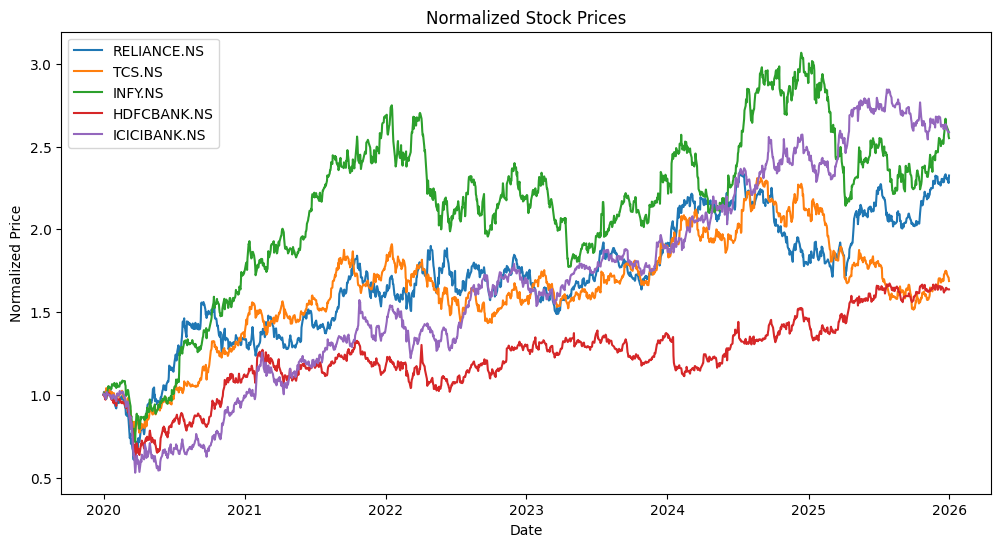

In [7]:
plt.figure(figsize=(12, 6))
for stock in normalized_prices.columns:
    plt.plot(normalized_prices.index, normalized_prices[stock], label=stock)
plt.xlabel('Date')
plt.ylabel('Normalized Price')
plt.title('Normalized Stock Prices')
plt.legend()
plt.show()

## Observation

The normalized series can be compared directly because they share the same starting value. The ending normalized value minus 1 gives the price return over the sample period, expressed as a decimal. Because `auto_adjust=True` is used, adjusted prices incorporate the data provider's adjustments for corporate actions.

## Daily Returns

Daily returns measure the proportional change from one trading session to the next:

$$
R_{i,t} = \frac{P_{i,t}-P_{i,t-1}}{P_{i,t-1}}.
$$

Returns are more comparable across stocks than raw prices and are commonly used in risk and portfolio calculations. The first return is undefined because no previous observation exists, so we remove missing rows before downstream calculations.

## Computing Daily Returns

In [8]:
returns = close_prices.pct_change().dropna()
returns.head()

Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Date,,,,,
2020-01-02,0.017025,-0.004590,-0.002918,0.006374,0.007173
2020-01-03,0.001205,0.019929,0.015381,-0.014261,-0.003237
2020-01-06,-0.023192,-0.000091,-0.009585,-0.021642,-0.024404
2020-01-07,0.015385,0.002454,-0.014820,0.015835,-0.005326
2020-01-08,-0.007510,0.022395,-0.013326,-0.002618,0.005833


In [9]:
avg_daily_returns = returns.mean()
avg_daily_returns

,0
Ticker,
RELIANCE.NS,0.000726
TCS.NS,0.000464
INFY.NS,0.000779
HDFCBANK.NS,0.000463
ICICIBANK.NS,0.000816


## Correlation Matrix

Correlation measures the strength and direction of the linear relationship between two return series. It ranges from -1 to +1: +1 indicates perfect positive linear association, 0 indicates no linear association, and -1 indicates perfect negative linear association.

Correlation is not causation, and low correlation can help diversification but does not guarantee lower risk in every market condition.

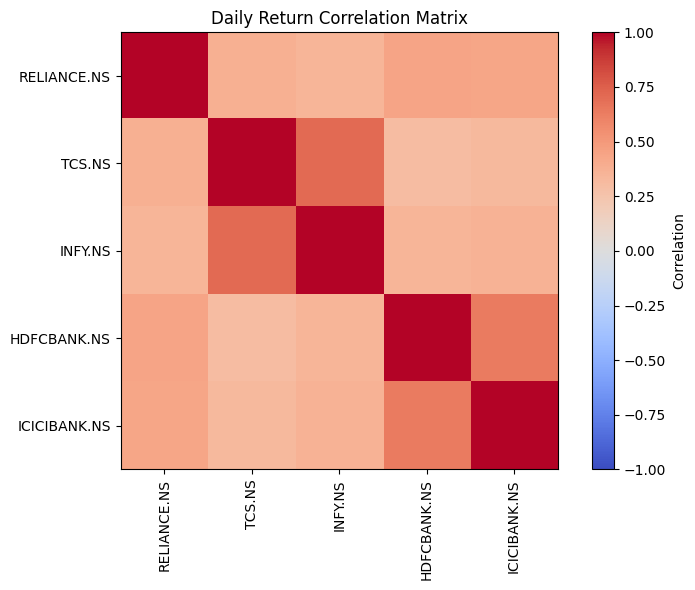

In [10]:
corr = returns.corr()

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Daily Return Correlation Matrix")
plt.tight_layout()
plt.show()

In [11]:
corr

Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Ticker,,,,,
RELIANCE.NS,1.000000,0.380524,0.349403,0.440879,0.430596
TCS.NS,0.380524,1.000000,0.710713,0.301035,0.321142
INFY.NS,0.349403,0.710713,1.000000,0.344535,0.364956
HDFCBANK.NS,0.440879,0.301035,0.344535,1.000000,0.635553
ICICIBANK.NS,0.430596,0.321142,0.364956,0.635553,1.000000


## Daily Volatility

Volatility is measured here by the sample standard deviation of daily returns. Larger values indicate more variable historical daily returns. This is a daily measure and is not annualized.

In [12]:
daily_volatility = returns.std()
daily_volatility

,0
Ticker,
RELIANCE.NS,0.017810
TCS.NS,0.014970
INFY.NS,0.017263
HDFCBANK.NS,0.016173
ICICIBANK.NS,0.018717


## Cumulative Price Return

The cumulative price return over the sample is calculated from the first and last adjusted closing prices:

$$
R_{total} = \left(\frac{P_{final}}{P_{initial}}-1\right)\times 100\%.
$$

This is a holding-period return, not an annualized return. It does not describe the path taken between the start and end dates.

In [13]:
total_returns_pct = close_prices.apply(lambda column: (column.dropna().iloc[-1] / column.dropna().iloc[0] - 1) * 100)
total_returns_pct.rename("Cumulative Price Return (%)")

,Cumulative Price Return (%)
Ticker,
RELIANCE.NS,132.540183
TCS.NS,68.744001
INFY.NS,155.136582
HDFCBANK.NS,63.691459
ICICIBANK.NS,158.678884


## Summary Table

The table combines average daily return, daily volatility, and cumulative price return. The first two columns are daily statistics in decimal units; the final column is a percentage over the full sample.

In [14]:
summary = pd.DataFrame({
    "Average Daily Return": avg_daily_returns,
    "Daily Volatility": daily_volatility,
    "Cumulative Price Return (%)": total_returns_pct
})
summary

,Average Daily Return,Daily Volatility,Cumulative Price Return (%)
Ticker,,,
RELIANCE.NS,0.000726,0.017810,132.540183
TCS.NS,0.000464,0.014970,68.744001
INFY.NS,0.000779,0.017263,155.136582
HDFCBANK.NS,0.000463,0.016173,63.691459
ICICIBANK.NS,0.000816,0.018717,158.678884


## Conclusions

Use the computed summary table rather than hard-coding rankings into markdown, because rankings can change when the data or sample period changes.

Questions to consider:

1. Which stock had the highest cumulative price return during this sample?
2. Which stock had the highest daily volatility?
3. Does the stock with the highest return also have the highest volatility?
4. How does correlation between stocks affect the potential benefits of diversification?

These observations describe this historical sample and should not be treated as predictions.